In [2]:
# make sure you ran workspace\ibm-qiskit-login.py first


print("let's try qiskit")
# https://docs.quantum.ibm.com/guides/hello-world

let's try qiskit


In [3]:
import qiskit_ibm_runtime
qiskit_ibm_runtime.version.get_version_info()

'0.38.0'

In [4]:
import qiskit
qiskit.version.get_version_info()

'2.0.0'

In [91]:
# new!  test boolean op circuits
# Part A - set up 

from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit import QuantumCircuit, transpile #, assemble
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import EstimatorV2 as Estimator, SamplerV2 as Sampler

# Read default credentials from disk
service = QiskitRuntimeService(channel = 'ibm_quantum')

qc = QuantumCircuit(8)

#inputs
qc.x(0)
qc.x(1)
#qc.x(2)
#qc.x(3) 

#qc.x(0)
#qc.x(1)
#qc.x(2)
#qc.x(3) 



#result qubits
qc.x(4)  
qc.x(5)  
qc.x(6)
qc.x(7)

qc.barrier()

# logic
qc.mcx([0,1],4)
qc.mcx([0,2],5)
qc.mcx([1,2],6)
qc.mcx([2,3],7)

# nots to reverse it
#qc.x(0)
#qc.x(1)
#qc.x(2)
#qc.x(3) 


qc.barrier()
qc.measure_all()



print(qc.draw())

C:\Users\thromadka\AppData\Local\Temp\ipykernel_23988\4146889440.py:10: DeprecationWarning: The "ibm_quantum" channel option is deprecated and will be sunset on 1 July. After this date, ibm_cloud will be the only valid channel. For information on migrating to the new IBM Quantum Platform on the "ibm_cloud" channel, review the migration guide https://quantum.cloud.ibm.com/docs/migration-guides/classic-iqp-to-cloud-iqp .
  service = QiskitRuntimeService(channel = 'ibm_quantum')


        ┌───┐ ░                      ░  ░ ┌─┐                     
   q_0: ┤ X ├─░───■────■─────────────░──░─┤M├─────────────────────
        ├───┤ ░   │    │             ░  ░ └╥┘┌─┐                  
   q_1: ┤ X ├─░───■────┼────■────────░──░──╫─┤M├──────────────────
        └───┘ ░   │    │    │        ░  ░  ║ └╥┘┌─┐               
   q_2: ──────░───┼────■────■────■───░──░──╫──╫─┤M├───────────────
              ░   │    │    │    │   ░  ░  ║  ║ └╥┘┌─┐            
   q_3: ──────░───┼────┼────┼────■───░──░──╫──╫──╫─┤M├────────────
        ┌───┐ ░ ┌─┴─┐  │    │    │   ░  ░  ║  ║  ║ └╥┘┌─┐         
   q_4: ┤ X ├─░─┤ X ├──┼────┼────┼───░──░──╫──╫──╫──╫─┤M├─────────
        ├───┤ ░ └───┘┌─┴─┐  │    │   ░  ░  ║  ║  ║  ║ └╥┘┌─┐      
   q_5: ┤ X ├─░──────┤ X ├──┼────┼───░──░──╫──╫──╫──╫──╫─┤M├──────
        ├───┤ ░      └───┘┌─┴─┐  │   ░  ░  ║  ║  ║  ║  ║ └╥┘┌─┐   
   q_6: ┤ X ├─░───────────┤ X ├──┼───░──░──╫──╫──╫──╫──╫──╫─┤M├───
        ├───┤ ░           └───┘┌─┴─┐ ░  ░  ║  ║  ║  ║  ║  ║ └╥

Job ID is d0x0xqe1wej00089j7d0
Counts for the meas output register: {'11111111': 6, '11100011': 99, '10110000': 70, '10100011': 247, '10000001': 61, '11000000': 32, '01110000': 15, '00010011': 37, '11110011': 195, '00000011': 18, '10011011': 21, '10010011': 301, '10000011': 149, '11110001': 229, '10110010': 58, '01010001': 16, '00110100': 5, '11110000': 97, '10010101': 17, '11000001': 82, '10010111': 57, '00100011': 31, '11100010': 48, '10010110': 11, '10000111': 29, '10110001': 176, '10110011': 532, '00100111': 24, '01010000': 6, '11010001': 162, '11010111': 18, '10110101': 43, '10110111': 73, '11100101': 22, '11110101': 60, '11010011': 103, '10010010': 38, '00110001': 17, '11000111': 13, '00100010': 4, '11010101': 29, '11000010': 31, '11010110': 9, '11110010': 86, '11110111': 26, '11110100': 18, '11100000': 49, '10110110': 18, '00010001': 10, '10100001': 86, '11111011': 10, '11100111': 10, '11100001': 135, '00000010': 1, '10001011': 4, '10110100': 12, '10101001': 7, '00100001': 6, '1

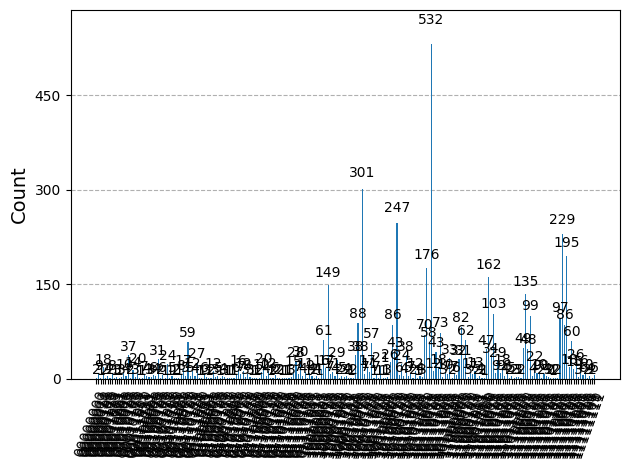

In [92]:
# Part B - run job
from qiskit.visualization import plot_histogram

# Optimize problem for quantum execution
backend = service.least_busy(operational=True, simulator=False)
pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
isa_circuit = pm.run(qc)

sampler = Sampler(mode=backend)
sampler.options.default_shots = 5000  #1000 is enough for the simple tests, #10000 or more for 4-qb MCX
job = sampler.run([isa_circuit])
print(f"Job ID is {job.job_id()}")
pub_result = job.result()[0]
print(f"Counts for the meas output register: {pub_result.data.meas.get_counts()}")


plot_histogram(pub_result.data.meas.get_counts())